In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"D:\AI-MSU")
RAW_DIR = PROJECT_DIR / "data" / "raw"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Raw folder found:", RAW_DIR.exists())
print("Processed folder:", PROCESSED_DIR)

Raw folder found: True
Processed folder: D:\AI-MSU\data\processed


In [2]:
files_to_check = ["logon.csv", "device.csv", "file.csv", "email.csv",
                  "http.csv", "psychometric.csv", "insiders.csv"]

file_info = []

for filename in files_to_check:
    found = list(RAW_DIR.rglob(filename))
    if found:
        for path in found:
            file_info.append([filename, str(path), round(path.stat().st_size / (1024**2), 2)])
    else:
        file_info.append([filename, "NOT FOUND", 0])

file_table = pd.DataFrame(file_info, columns=["File", "Path", "Size_MB"])
display(file_table)

,File,Path,Size_MB
0,logon.csv,D:\AI-MSU\data\raw\logon.csv,55.80
1,device.csv,D:\AI-MSU\data\raw\device.csv,27.64
2,file.csv,D:\AI-MSU\data\raw\file.csv,184.11
3,email.csv,D:\AI-MSU\data\raw\email.csv,1299.00
4,http.csv,D:\AI-MSU\data\raw\http.csv,13862.86
5,psychometric.csv,D:\AI-MSU\data\raw\psychometric.csv,0.04
6,insiders.csv,D:\AI-MSU\data\raw\answers\insiders.csv,0.01


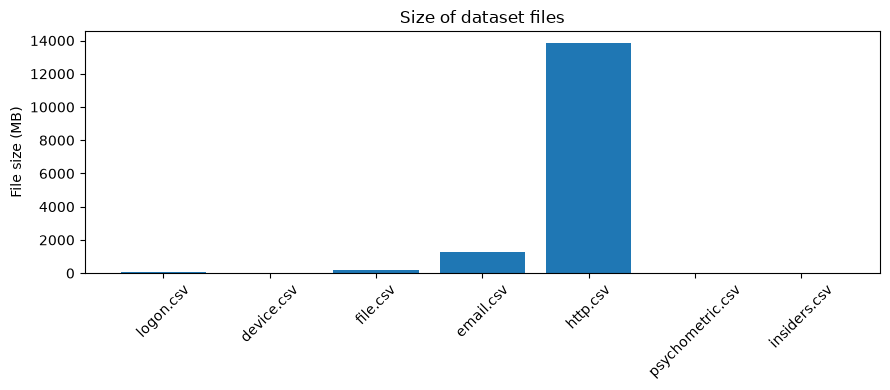

In [3]:
plt.figure(figsize=(9, 4))
plt.bar(file_table["File"], file_table["Size_MB"])
plt.xticks(rotation=45)
plt.ylabel("File size (MB)")
plt.title("Size of dataset files")
plt.tight_layout()
plt.show()

In [4]:
for filename in files_to_check:
    found = list(RAW_DIR.rglob(filename))
    if found:
        print("\n", filename)
        print(pd.read_csv(found[0], nrows=5).head())
        print("Columns:", pd.read_csv(found[0], nrows=0).columns.tolist())


 logon.csv
                         id                 date     user       pc activity
0  {X1D9-S0ES98JV-5357PWMI}  01/02/2010 06:49:00  NGF0157  PC-6056    Logon
1  {G2B3-L6EJ61GT-2222RKSO}  01/02/2010 06:50:00  LRR0148  PC-4275    Logon
2  {U6Q3-U0WE70UA-3770UREL}  01/02/2010 06:53:04  LRR0148  PC-4124    Logon
3  {I0N5-R7NA26TG-6263KNGM}  01/02/2010 07:00:00  IRM0931  PC-7188    Logon
4  {D1S0-N6FH62BT-5398KANK}  01/02/2010 07:00:00  MOH0273  PC-6699    Logon
Columns: ['id', 'date', 'user', 'pc', 'activity']

 device.csv
                         id                 date     user       pc    activity
0  {J1S3-L9UU75BQ-7790ATPL}  01/02/2010 07:21:06  MOH0273  PC-6699     Connect
1  {N7B5-Y7BB27SI-2946PUJK}  01/02/2010 07:37:41  MOH0273  PC-6699  Disconnect
2  {U1V9-Z7XT67KV-5649MYHI}  01/02/2010 07:59:11  HPH0075  PC-2417     Connect
3  {H0Z7-E6GB57XZ-1603MOXD}  01/02/2010 07:59:49  IIW0249  PC-0843     Connect
4  {L7P2-G4PX02RX-7999GYOY}  01/02/2010 08:04:26  IIW0249  PC-0843  Discon